# Laboratorio 09 — Regresión lineal, regularización y validación cruzada en PySpark
**Minería de Datos — UNSAAC**

Este notebook resuelve las cinco actividades de `Guia_9_Regresion_Lineal_PySpark.pdf` usando `obras_publicas.csv`.

**Cómo ejecutarlo en Google Colab**
1. Ejecutar las celdas en orden.
2. Cuando se solicite, subir `obras_publicas.csv`.
3. Esperar a que finalicen los entrenamientos de las actividades 3, 4 y 5.
4. Guardar capturas de las salidas y gráficos en una carpeta `capturas/` para incorporarlas al informe de Overleaf.

> Se excluyen `costo_final_soles` y `plazo_real_dias` de los predictores porque contienen información conocida al finalizar la obra (fuga de información).

## 0. Instalación, configuración y carga del dataset

In [1]:
# Instalar PySpark en el entorno de Google Colab.
!pip -q install pyspark

In [3]:
import os
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files
from pyspark.sql import SparkSession, functions as F
from pyspark.sql.types import DoubleType
from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler, StandardScaler, StringIndexer, OneHotEncoder, PolynomialExpansion
from pyspark.ml.regression import LinearRegression
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.ml.tuning import ParamGridBuilder, CrossValidator

# Crear SparkSession. En Colab se ejecuta localmente usando todos los núcleos disponibles.
spark = (SparkSession.builder
         .appName("Laboratorio09_Regresion_ObrasPublicas")
         .master("local[*]")
         .config("spark.driver.memory", "4g")
         .getOrCreate())
spark.sparkContext.setLogLevel("WARN")

# Subir el CSV desde el equipo local.
uploaded = files.upload()
csv_name = next((name for name in uploaded if name.lower().endswith(".csv")), None)
if csv_name is None:
    raise FileNotFoundError("Debe subir el archivo obras_publicas.csv")

df = spark.read.csv(csv_name, header=True, inferSchema=True)
print("Filas:", df.count(), "| Columnas:", len(df.columns))
df.printSchema()
df.show(5, truncate=False)

Saving obras_publicas.csv to obras_publicas.csv
Filas: 20000 | Columnas: 18
root
 |-- id_obra: string (nullable = true)
 |-- anio: integer (nullable = true)
 |-- region: string (nullable = true)
 |-- tipo_entidad: string (nullable = true)
 |-- tipo_obra: string (nullable = true)
 |-- presupuesto_soles: double (nullable = true)
 |-- metrado_m2: double (nullable = true)
 |-- plazo_programado_dias: double (nullable = true)
 |-- mes_inicio: integer (nullable = true)
 |-- altitud_msnm: double (nullable = true)
 |-- distancia_capital_km: double (nullable = true)
 |-- num_postores: integer (nullable = true)
 |-- experiencia_contratista_anios: double (nullable = true)
 |-- num_trabajadores: integer (nullable = true)
 |-- num_adendas: integer (nullable = true)
 |-- costo_final_soles: double (nullable = true)
 |-- plazo_real_dias: double (nullable = true)
 |-- sobrecosto_pct: double (nullable = true)

+-------+----+--------+-----------------------+-----------+-----------------+----------+-------

## Actividad 1. Cálculo manual

Se trabaja con las cinco obras de la tabla de la guía. Se calcula la regresión bivariada con `adendas`, sus residuos y métricas; luego la regresión múltiple con `adendas` y `altitud`. Finalmente, se comparan SSE, R² y R² ajustado y se verifica con NumPy.

In [4]:
# Datos transcritos de la tabla de la Actividad 1 de la guía.
manual = pd.DataFrame({
    "obra": ["O1", "O2", "O3", "O4", "O5"],
    "adendas": [0, 1, 2, 3, 4],
    "altitud_miles": [0.4, 2.3, 3.3, 3.8, 4.0],
    "presupuesto_millones": [0.8, 1.5, 2.4, 5.0, 3.2],
    "sobrecosto_pct": [3, 7, 12, 14, 19]
})
display(manual)

x = manual["adendas"].to_numpy(dtype=float)
z = manual["altitud_miles"].to_numpy(dtype=float)
y = manual["sobrecosto_pct"].to_numpy(dtype=float)
n = len(y)

# (a) Regresión bivariada: w = cov(X,Y)/var(X); b = media(Y)-w*media(X).
w_simple = np.sum((x-x.mean())*(y-y.mean())) / np.sum((x-x.mean())**2)
b_simple = y.mean() - w_simple*x.mean()
yhat_simple = b_simple + w_simple*x
res_simple = y-yhat_simple

# (b) Métricas y propiedades de los residuos.
SSE_simple = np.sum(res_simple**2)
SST = np.sum((y-y.mean())**2)
R2_simple = 1 - SSE_simple/SST
MAE_simple = np.mean(np.abs(res_simple))
RMSE_simple = np.sqrt(np.mean(res_simple**2))

tabla_simple = manual[["obra","adendas","sobrecosto_pct"]].copy()
tabla_simple["prediccion"] = yhat_simple
tabla_simple["residuo"] = res_simple
tabla_simple["residuo_cuadrado"] = res_simple**2
display(tabla_simple)

print(f"w = {w_simple:.6f}; b = {b_simple:.6f}")
print(f"SSE={SSE_simple:.6f}; SST={SST:.6f}; R²={R2_simple:.6f}")
print(f"MAE={MAE_simple:.6f}; RMSE={RMSE_simple:.6f}")
print(f"Σ residuos = {res_simple.sum():.10f}")
print(f"Σ x_i * residuo_i = {np.sum(x*res_simple):.10f}")

,obra,adendas,altitud_miles,presupuesto_millones,sobrecosto_pct
0,O1,0,0.4,0.8,3
1,O2,1,2.3,1.5,7
2,O3,2,3.3,2.4,12
3,O4,3,3.8,5.0,14
4,O5,4,4.0,3.2,19


,obra,adendas,sobrecosto_pct,prediccion,residuo,residuo_cuadrado
0,O1,0,3,3.2,-0.2,0.04
1,O2,1,7,7.1,-0.1,0.01
2,O3,2,12,11.0,1.0,1.00
3,O4,3,14,14.9,-0.9,0.81
4,O5,4,19,18.8,0.2,0.04


w = 3.900000; b = 3.200000
SSE=1.900000; SST=154.000000; R²=0.987662
MAE=0.480000; RMSE=0.616441
Σ residuos = 0.0000000000
Σ x_i * residuo_i = 0.0000000000


In [5]:
# (c) Regresión múltiple: D̃ contiene la columna de unos para el intercepto.
D_tilde = np.column_stack([np.ones(n), x, z])
DtD = D_tilde.T @ D_tilde
Dty = D_tilde.T @ y
w_multiple = np.linalg.solve(DtD, Dty)  # ecuaciones normales
yhat_multiple = D_tilde @ w_multiple
res_multiple = y-yhat_multiple
SSE_multiple = np.sum(res_multiple**2)
R2_multiple = 1-SSE_multiple/SST

# R² ajustado: 1 - (1-R²)*(n-1)/(n-d-1), d = número de predictores.
d_simple, d_multiple = 1, 2
R2adj_simple = 1-(1-R2_simple)*(n-1)/(n-d_simple-1)
R2adj_multiple = 1-(1-R2_multiple)*(n-1)/(n-d_multiple-1)
corr_adendas_altitud = np.corrcoef(x,z)[0,1]

print("Matriz D̃ᵀD̃:\n", DtD)
print("Vector D̃ᵀy:\n", Dty)
print("Coeficientes [intercepto, adendas, altitud]:", np.round(w_multiple,6))
print(f"SSE múltiple={SSE_multiple:.6f}; R² múltiple={R2_multiple:.6f}")
print(f"R² ajustado bivariado={R2adj_simple:.6f}")
print(f"R² ajustado múltiple={R2adj_multiple:.6f}")
print(f"Correlación adendas-altitud={corr_adendas_altitud:.6f}")

Matriz D̃ᵀD̃:
 [[ 5.   10.   13.8 ]
 [10.   30.   36.3 ]
 [13.8  36.3  46.78]]
Vector D̃ᵀy:
 [ 55.  149.  186.1]
Coeficientes [intercepto, adendas, altitud]: [2.863936 3.613357 0.329475]
SSE múltiple=1.778094; R² múltiple=0.988454
R² ajustado bivariado=0.983550
R² ajustado múltiple=0.976908
Correlación adendas-altitud=0.933167


In [6]:
# (d) Comparación de modelos.
comparacion_manual = pd.DataFrame([
    ["Bivariado (adendas)", SSE_simple, R2_simple, R2adj_simple],
    ["Múltiple (adendas + altitud)", SSE_multiple, R2_multiple, R2adj_multiple]
], columns=["Modelo","SSE","R2","R2_ajustado"])
display(comparacion_manual)

# Comprobación independiente mediante mínimos cuadrados de NumPy.
coef_lstsq, *_ = np.linalg.lstsq(D_tilde, y, rcond=None)
print("Coeficientes con np.linalg.lstsq:", np.round(coef_lstsq,6))
print("La regresión múltiple reduce ligeramente SSE y mejora R² ajustado en esta muestra.")
print("La correlación adendas-altitud es alta; con solo cinco observaciones conviene ser cauteloso.")

,Modelo,SSE,R2,R2_ajustado
0,Bivariado (adendas),1.900000,0.987662,0.983550
1,Múltiple (adendas + altitud),1.778094,0.988454,0.976908


Coeficientes con np.linalg.lstsq: [2.863936 3.613357 0.329475]
La regresión múltiple reduce ligeramente SSE y mejora R² ajustado en esta muestra.
La correlación adendas-altitud es alta; con solo cinco observaciones conviene ser cauteloso.


## Actividad 2. Regularización y validación cruzada a mano

Se implementan las fórmulas Ridge y Lasso indicadas en la guía, usando los datos centrados. Después se aplica LOO (5 folds): en cada iteración se deja una obra para validación y se ajusta el modelo con las otras cuatro.

In [7]:
# (a) Ridge bivariado: penalización alpha sobre la pendiente; el intercepto no se penaliza.
ridge_rows = []
Sxy = np.sum((x-x.mean())*(y-y.mean()))
Sxx = np.sum((x-x.mean())**2)
for alpha in [0, 5, 10, 40]:
    w_ridge = Sxy/(Sxx+alpha)
    b_ridge = y.mean()-w_ridge*x.mean()
    pred_ridge = b_ridge+w_ridge*x
    ridge_rows.append([alpha,w_ridge,b_ridge,np.sum((y-pred_ridge)**2)])
ridge_manual = pd.DataFrame(ridge_rows,columns=["alpha","w","b","SSE"])
display(ridge_manual)

# (b) Lasso con umbral suave S_alpha(z)=sign(z)*max(0,|z|-alpha).
lasso_rows = []
for alpha in [0, 10, 20, 40]:
    soft = np.sign(Sxy)*max(0,abs(Sxy)-alpha)
    w_lasso = soft/Sxx
    b_lasso = y.mean()-w_lasso*x.mean()
    pred_lasso = b_lasso+w_lasso*x
    lasso_rows.append([alpha,Sxy,soft,w_lasso,b_lasso,np.sum((y-pred_lasso)**2)])
lasso_manual = pd.DataFrame(lasso_rows,columns=["alpha","Sxy","umbral_suave","w","b","SSE"])
display(lasso_manual)
print("Cuando alpha alcanza o supera |Sxy| =", Sxy, ", la pendiente Lasso queda exactamente en cero.")
print("Con w=0, el modelo predice la media de sobrecosto:", y.mean())

,alpha,w,b,SSE
0,0,3.90,3.20,1.900
1,5,2.60,5.80,18.800
2,10,1.95,7.10,39.925
3,40,0.78,9.44,99.244


,alpha,Sxy,umbral_suave,w,b,SSE
0,0,39.0,39.0,3.9,3.2,1.9
1,10,39.0,29.0,2.9,5.2,11.9
2,20,39.0,19.0,1.9,7.2,41.9
3,40,39.0,0.0,0.0,11.0,154.0


Cuando alpha alcanza o supera |Sxy| = 39.0 , la pendiente Lasso queda exactamente en cero.
Con w=0, el modelo predice la media de sobrecosto: 11.0


In [8]:
# (c) y (d) Validación cruzada LOO para el modelo simple y el múltiple.
def loo_simple(xv, yv):
    registros=[]
    for i in range(len(yv)):
        mask=np.arange(len(yv))!=i
        xt, yt=xv[mask], yv[mask]
        w=np.sum((xt-xt.mean())*(yt-yt.mean()))/np.sum((xt-xt.mean())**2)
        b=yt.mean()-w*xt.mean()
        pred=b+w*xv[i]
        registros.append([i+1, f"excepto O{i+1}", f"O{i+1}", w,b,pred,(yv[i]-pred)**2])
    out=pd.DataFrame(registros,columns=["fold","entrenamiento","validacion","w","b","prediccion","error_cuadrado"])
    return out, np.sqrt(out["error_cuadrado"].mean())

def loo_multiple(xv,zv,yv):
    registros=[]
    for i in range(len(yv)):
        mask=np.arange(len(yv))!=i
        Xtr=np.column_stack([np.ones(mask.sum()),xv[mask],zv[mask]])
        coef=np.linalg.solve(Xtr.T@Xtr,Xtr.T@yv[mask])
        pred=np.array([1,xv[i],zv[i]])@coef
        registros.append([i+1, f"excepto O{i+1}", f"O{i+1}", coef[1],coef[2],coef[0],pred,(yv[i]-pred)**2])
    out=pd.DataFrame(registros,columns=["fold","entrenamiento","validacion","w_adendas","w_altitud","b","prediccion","error_cuadrado"])
    return out, np.sqrt(out["error_cuadrado"].mean())

loo_biv, rmse_loo_biv=loo_simple(x,y)
loo_mult, rmse_loo_mult=loo_multiple(x,z,y)
display(loo_biv)
display(loo_mult)
print(f"RMSE LOO bivariado: {rmse_loo_biv:.6f}")
print(f"RMSE LOO múltiple: {rmse_loo_mult:.6f}")
print("El menor RMSE LOO indica mejor generalización en estas cinco obras.")

,fold,entrenamiento,validacion,w,b,prediccion,error_cuadrado
0,1,excepto O1,O1,3.800000,3.500000,3.500000,0.250000
1,2,excepto O2,O2,3.885714,3.257143,7.142857,0.020408
2,3,excepto O3,O3,3.900000,2.950000,10.750000,1.562500
3,4,excepto O4,O4,4.028571,3.200000,15.285714,1.653061
4,5,excepto O5,O5,3.800000,3.300000,18.500000,0.250000


,fold,entrenamiento,validacion,w_adendas,w_altitud,b,prediccion,error_cuadrado
0,1,excepto O1,O1,3.592593,0.370370,2.777778,2.925926,0.005487
1,2,excepto O2,O2,3.434951,0.485437,2.875728,7.427184,0.182487
2,3,excepto O3,O3,4.249835,-0.402109,3.305867,10.478576,2.314731
3,4,excepto O4,O4,3.568410,0.544110,2.645008,15.417855,2.010314
4,5,excepto O5,O5,2.405622,1.244980,2.341365,16.943775,4.228061


RMSE LOO bivariado: 0.864404
RMSE LOO múltiple: 1.322201
El menor RMSE LOO indica mejor generalización en estas cinco obras.


## Actividad 3. Exploración del dataset y regresiones bivariada y múltiple

Se exploran conteos y sobrecostos promedio por `tipo_obra`, `region` y `num_adendas`; se calcula la matriz de correlación; se crean `log_presupuesto`, `log_metrado` y `lluvias`; se divide 80/20 con semilla 42 y se estandarizan los diez atributos indicados en la guía.

In [9]:
# Validaciones básicas del dataset y tratamiento de nulos.
print("Dimensiones:", df.count(), len(df.columns))
print("Nulos por columna:")
df.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in df.columns]).show(truncate=False)

# Conteo y sobrecosto promedio por las categorías solicitadas.
for colname in ["tipo_obra","region","num_adendas"]:
    print(f"Resumen por {colname}")
    (df.groupBy(colname)
       .agg(F.count("*").alias("numero_obras"),
            F.avg("sobrecosto_pct").alias("sobrecosto_promedio"))
       .orderBy(colname).show(30,truncate=False))

# Correlaciones entre variables numéricas y variable respuesta.
numeric_cols = [c for c,t in df.dtypes if t in ("int","bigint","double","float","long")]
corr_cols = [c for c in numeric_cols if c not in ["costo_final_soles","plazo_real_dias"]]
corr_rows=[]
for c in corr_cols:
    corr_rows.append((c,df.stat.corr(c,"sobrecosto_pct")))
corr_pd=pd.DataFrame(corr_rows,columns=["atributo","correlacion_con_sobrecosto"]).sort_values("correlacion_con_sobrecosto",key=abs,ascending=False)
display(corr_pd)

# Buscar el par de atributos numéricos con mayor correlación absoluta, excluyendo la diagonal.
pair_corr=[]
for i,c1 in enumerate(corr_cols):
    for c2 in corr_cols[i+1:]:
        value=df.stat.corr(c1,c2)
        if value is not None:
            pair_corr.append((c1,c2,value,abs(value)))
pair_corr_df=pd.DataFrame(pair_corr,columns=["atributo_1","atributo_2","correlacion","abs_correlacion"]).sort_values("abs_correlacion",ascending=False)
display(pair_corr_df.head(10))

Dimensiones: 20000 18
Nulos por columna:
+-------+----+------+------------+---------+-----------------+----------+---------------------+----------+------------+--------------------+------------+-----------------------------+----------------+-----------+-----------------+---------------+--------------+
|id_obra|anio|region|tipo_entidad|tipo_obra|presupuesto_soles|metrado_m2|plazo_programado_dias|mes_inicio|altitud_msnm|distancia_capital_km|num_postores|experiencia_contratista_anios|num_trabajadores|num_adendas|costo_final_soles|plazo_real_dias|sobrecosto_pct|
+-------+----+------+------------+---------+-----------------+----------+---------------------+----------+------------+--------------------+------------+-----------------------------+----------------+-----------+-----------------+---------------+--------------+
|0      |0   |0     |0           |0        |0                |0         |0                    |0         |0           |0                   |0           |0                   

,atributo,correlacion_con_sobrecosto
11,sobrecosto_pct,1.000000
10,num_adendas,0.678189
5,altitud_msnm,0.378566
6,distancia_capital_km,0.222149
8,experiencia_contratista_anios,-0.209168
1,presupuesto_soles,0.159565
2,metrado_m2,0.157036
3,plazo_programado_dias,0.122818
4,mes_inicio,-0.105920
7,num_postores,-0.092139


,atributo_1,atributo_2,correlacion,abs_correlacion
11,presupuesto_soles,metrado_m2,0.986312,0.986312
65,num_adendas,sobrecosto_pct,0.678189,0.678189
12,presupuesto_soles,plazo_programado_dias,0.458386,0.458386
21,metrado_m2,plazo_programado_dias,0.450461,0.450461
50,altitud_msnm,sobrecosto_pct,0.378566,0.378566
49,altitud_msnm,num_adendas,0.261427,0.261427
55,distancia_capital_km,sobrecosto_pct,0.222149,0.222149
62,experiencia_contratista_anios,sobrecosto_pct,-0.209168,0.209168
20,presupuesto_soles,sobrecosto_pct,0.159565,0.159565
29,metrado_m2,sobrecosto_pct,0.157036,0.157036


In [10]:
# Crear variables derivadas exactamente como en la guía.
lluvia = F.col("mes_inicio").isin(12,1,2,3).cast("int")
df_model = (df
    .withColumn("log_presupuesto",F.log1p("presupuesto_soles"))
    .withColumn("log_metrado",F.log1p("metrado_m2"))
    .withColumn("lluvias",lluvia)
    .dropna(subset=["sobrecosto_pct","num_adendas","altitud_msnm",
                    "distancia_capital_km","experiencia_contratista_anios",
                    "num_postores","log_presupuesto","log_metrado",
                    "plazo_programado_dias","num_trabajadores","lluvias"]))

atributos = ["num_adendas","altitud_msnm","distancia_capital_km",
             "experiencia_contratista_anios","num_postores","log_presupuesto",
             "log_metrado","plazo_programado_dias","num_trabajadores","lluvias"]
train, test = df_model.randomSplit([0.8,0.2],seed=42)

# Ajustar el ensamblador y el escalador SOLO con entrenamiento para evitar fuga.
prep = Pipeline(stages=[
    VectorAssembler(inputCols=atributos,outputCol="raw",handleInvalid="skip"),
    StandardScaler(inputCol="raw",outputCol="features",withMean=True,withStd=True)
]).fit(train)
train_p=prep.transform(train).cache()
test_p=prep.transform(test).cache()
print("Entrenamiento:",train_p.count(),"Prueba:",test_p.count())

Entrenamiento: 16052 Prueba: 3948


In [11]:
# Función de evaluación uniforme en entrenamiento y prueba.
def evaluar_modelo(modelo, train_data, test_data, nombre, d):
    ev=RegressionEvaluator(labelCol="sobrecosto_pct",predictionCol="prediction")
    resultados=[]
    for conjunto,data in [("Entrenamiento",train_data),("Prueba",test_data)]:
        pred=modelo.transform(data)
        rmse=ev.evaluate(pred,{ev.metricName:"rmse"})
        mae=ev.evaluate(pred,{ev.metricName:"mae"})
        r2=ev.evaluate(pred,{ev.metricName:"r2"})
        nobs=data.count()
        r2adj=1-(1-r2)*(nobs-1)/(nobs-d-1) if nobs>d+1 else float("nan")
        resultados.append([nombre,conjunto,rmse,mae,r2,r2adj])
    return resultados

# (a) Bivariada con num_adendas. La guía indica estandarizar; se crea vector de una columna.
prep_biv=Pipeline(stages=[
    VectorAssembler(inputCols=["num_adendas"],outputCol="raw_biv"),
    StandardScaler(inputCol="raw_biv",outputCol="features",withMean=True,withStd=True)
]).fit(train)
train_biv=prep_biv.transform(train).cache()
test_biv=prep_biv.transform(test).cache()
lr_biv=LinearRegression(featuresCol="features",labelCol="sobrecosto_pct",solver="normal")
modelo_biv=lr_biv.fit(train_biv)
print("Bivariado intercepto:",modelo_biv.intercept,"coeficientes:",modelo_biv.coefficients)

Bivariado intercepto: 10.959658609519124 coeficientes: [3.8733582902949197]


In [12]:
# (b) Múltiple con los diez atributos.
lr_multi=LinearRegression(featuresCol="features",labelCol="sobrecosto_pct",solver="normal")
modelo_multi=lr_multi.fit(train_p)
print("Múltiple intercepto:",modelo_multi.intercept)
print("Pesos:",dict(zip(atributos,[float(v) for v in modelo_multi.coefficients])))

metricas_act3 = evaluar_modelo(modelo_biv,train_biv,test_biv,"Bivariado",1)
metricas_act3 += evaluar_modelo(modelo_multi,train_p,test_p,"Múltiple",len(atributos))
display(pd.DataFrame(metricas_act3,columns=["modelo","conjunto","RMSE","MAE","R2","R2_ajustado"]))
print("El signo de log_metrado se interpreta condicionado a los demás atributos;")
print("un signo negativo puede reflejar economías de escala y/o correlación con presupuesto y tamaño.")

Múltiple intercepto: 10.95965860951912
Pesos: {'num_adendas': 3.067801526695728, 'altitud_msnm': 1.3882741766892575, 'distancia_capital_km': 0.9193893123056616, 'experiencia_contratista_anios': -0.8596997909306441, 'num_postores': -0.5404678988136571, 'log_presupuesto': 0.8888508657533885, 'log_metrado': -0.10203871888728908, 'plazo_programado_dias': -0.05755256019620909, 'num_trabajadores': -0.0018726916343803448, 'lluvias': 1.1451772094758963}


,modelo,conjunto,RMSE,MAE,R2,R2_ajustado
0,Bivariado,Entrenamiento,4.250865,3.395345,0.453618,0.453584
1,Bivariado,Prueba,4.248983,3.386656,0.483789,0.483658
2,Múltiple,Entrenamiento,3.607838,2.877802,0.606417,0.606172
3,Múltiple,Prueba,3.600398,2.873951,0.629355,0.628413


El signo de log_metrado se interpreta condicionado a los demás atributos;
un signo negativo puede reflejar economías de escala y/o correlación con presupuesto y tamaño.


In [13]:
# Comprobar los pesos de regresión múltiple con ecuaciones normales y QR en una muestra.
# Se usa una muestra para que la conversión a pandas no lleve todo el dataset al driver.
m = (train_p.sample(withReplacement=False,fraction=0.05,seed=42)
     .select("features","sobrecosto_pct").toPandas())
X = np.column_stack([np.ones(len(m)),np.stack(m.features.apply(lambda v:v.toArray()))])
yy = m.sobrecosto_pct.to_numpy()
# Ecuaciones normales; puede ser sensible si hay multicolinealidad.
w_normal = np.linalg.solve(X.T@X,X.T@yy)
# Factorización QR, alternativa numéricamente más estable.
Q,R = np.linalg.qr(X)
w_qr = np.linalg.solve(R,Q.T@yy)
print("Pesos ecuaciones normales:",np.round(w_normal,4))
print("Pesos QR:",np.round(w_qr,4))
print("Diferencia máxima:",np.max(np.abs(w_normal-w_qr)))
print("Matriz de correlación de los atributos de la muestra:")
display(pd.DataFrame(np.corrcoef(X[:,1:],rowvar=False),index=atributos,columns=atributos).round(2))

Pesos ecuaciones normales: [10.9684  3.1306  1.4141  0.746  -0.7412 -0.6341  0.6966  0.0256 -0.0823
  0.086   1.1816]
Pesos QR: [10.9684  3.1306  1.4141  0.746  -0.7412 -0.6341  0.6966  0.0256 -0.0823
  0.086   1.1816]
Diferencia máxima: 1.6542323066914832e-14
Matriz de correlación de los atributos de la muestra:


,num_adendas,altitud_msnm,distancia_capital_km,experiencia_contratista_anios,num_postores,log_presupuesto,log_metrado,plazo_programado_dias,num_trabajadores,lluvias
num_adendas,1.00,0.20,0.09,-0.08,0.06,0.06,0.06,0.04,-0.02,0.16
altitud_msnm,0.20,1.00,-0.01,-0.00,-0.00,0.00,-0.00,0.04,-0.04,-0.01
distancia_capital_km,0.09,-0.01,1.00,0.05,-0.00,-0.03,-0.03,-0.04,-0.05,0.01
experiencia_contratista_anios,-0.08,-0.00,0.05,1.00,0.02,0.07,0.06,0.08,0.02,0.05
num_postores,0.06,-0.00,-0.00,0.02,1.00,-0.05,-0.05,-0.04,-0.00,0.01
log_presupuesto,0.06,0.00,-0.03,0.07,-0.05,1.00,0.99,0.62,0.04,-0.05
log_metrado,0.06,-0.00,-0.03,0.06,-0.05,0.99,1.00,0.61,0.04,-0.06
plazo_programado_dias,0.04,0.04,-0.04,0.08,-0.04,0.62,0.61,1.00,0.03,-0.03
num_trabajadores,-0.02,-0.04,-0.05,0.02,-0.00,0.04,0.04,0.03,1.00,-0.02
lluvias,0.16,-0.01,0.01,0.05,0.01,-0.05,-0.06,-0.03,-0.02,1.00


In [14]:
# Comparar solver normal y l-bfgs sobre el mismo conjunto de entrenamiento.
m_normal=LinearRegression(featuresCol="features",labelCol="sobrecosto_pct",solver="normal").fit(train_p)
m_lbfgs=LinearRegression(featuresCol="features",labelCol="sobrecosto_pct",solver="l-bfgs").fit(train_p)
print("Intercepto normal / l-bfgs:",m_normal.intercept,m_lbfgs.intercept)
print("Máxima diferencia absoluta entre coeficientes:",
      np.max(np.abs(np.array(m_normal.coefficients)-np.array(m_lbfgs.coefficients))))

Intercepto normal / l-bfgs: 10.95965860951912 10.959658609519098
Máxima diferencia absoluta entre coeficientes: 1.635393390986284e-07


## Actividad 4. Caminos de coeficientes, categóricas y expansión polinómica

Se comparan Ridge (`elasticNetParam=0`) y Lasso (`elasticNetParam=1`) para los seis valores de `regParam`. Luego se incorporan `tipo_obra` y `region` mediante `StringIndexer` y `OneHotEncoder`; por separado, se ajusta una expansión polinómica de grado 2. Finalmente se contrasta la variable binaria `lluvias` con `mes_inicio`.

In [15]:
reg_values=[0,0.001,0.01,0.1,0.5,1.0]
path_rows=[]
models_reg={}
for en,penalty in [(0.0,"Ridge"),(1.0,"Lasso")]:
    for reg in reg_values:
        model=LinearRegression(featuresCol="features",labelCol="sobrecosto_pct",
                               regParam=reg,elasticNetParam=en,solver="l-bfgs").fit(train_p)
        models_reg[(penalty,reg)]=model
        pred=model.transform(test_p)
        ev=RegressionEvaluator(labelCol="sobrecosto_pct",predictionCol="prediction")
        path_rows.append([penalty,reg,
            ev.evaluate(pred,{ev.metricName:"rmse"}),
            ev.evaluate(pred,{ev.metricName:"mae"}),
            ev.evaluate(pred,{ev.metricName:"r2"})])
        for name,coef in zip(atributos,model.coefficients):
            # Guardar cada peso para el gráfico de trayectoria.
            pass
coef_rows=[]
for (penalty,reg),model in models_reg.items():
    for name,coef in zip(atributos,model.coefficients):
        coef_rows.append([penalty,reg,name,float(coef)])
coef_df=pd.DataFrame(coef_rows,columns=["penalizacion","regParam","atributo","peso"])
metricas_reg=pd.DataFrame(path_rows,columns=["modelo","regParam","RMSE_prueba","MAE_prueba","R2_prueba"])
display(metricas_reg)

,modelo,regParam,RMSE_prueba,MAE_prueba,R2_prueba
0,Ridge,0.000,3.600398,2.873951,0.629355
1,Ridge,0.001,3.600421,2.873987,0.629350
2,Ridge,0.010,3.600635,2.874308,0.629306
3,Ridge,0.100,3.603263,2.877438,0.628765
4,Ridge,0.500,3.621613,2.893542,0.624974
5,Ridge,1.000,3.657301,2.921170,0.617546
6,Lasso,0.000,3.600398,2.873951,0.629355
7,Lasso,0.001,3.600481,2.874149,0.629338
8,Lasso,0.010,3.600925,2.874365,0.629246
9,Lasso,0.100,3.615237,2.885895,0.626293


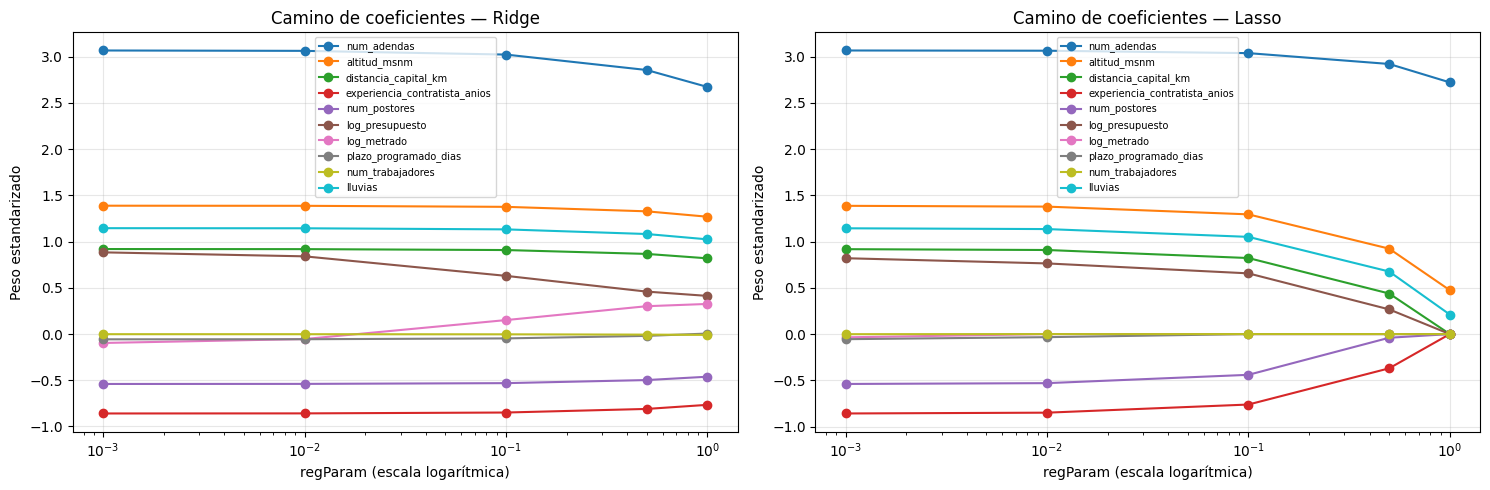

num_adendas primer regParam con peso aproximadamente cero: None
altitud_msnm primer regParam con peso aproximadamente cero: None
distancia_capital_km primer regParam con peso aproximadamente cero: 1.0
experiencia_contratista_anios primer regParam con peso aproximadamente cero: 1.0
num_postores primer regParam con peso aproximadamente cero: 1.0
log_presupuesto primer regParam con peso aproximadamente cero: 1.0
log_metrado primer regParam con peso aproximadamente cero: 0.01
plazo_programado_dias primer regParam con peso aproximadamente cero: 0.1
num_trabajadores primer regParam con peso aproximadamente cero: 0.01
lluvias primer regParam con peso aproximadamente cero: None


In [16]:
# Gráfico del camino de coeficientes. Se omite regParam=0 en eje logarítmico.
fig,axes=plt.subplots(1,2,figsize=(15,5))
for ax,penalty in zip(axes,["Ridge","Lasso"]):
    subset=coef_df[(coef_df.penalizacion==penalty)&(coef_df.regParam>0)]
    for atributo in atributos:
        serie=subset[subset.atributo==atributo]
        ax.plot(serie.regParam,serie.peso,marker="o",label=atributo)
    ax.set_xscale("log")
    ax.set_title(f"Camino de coeficientes — {penalty}")
    ax.set_xlabel("regParam (escala logarítmica)")
    ax.set_ylabel("Peso estandarizado")
    ax.grid(True,alpha=.3)
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

# Identificar cuándo Lasso lleva cada coeficiente a cero (tolerancia numérica).
lasso_coef=coef_df[coef_df.penalizacion=="Lasso"]
for atributo in atributos:
    serie=lasso_coef[lasso_coef.atributo==atributo].sort_values("regParam")
    ceros=serie[np.isclose(serie.peso,0,atol=1e-5)]
    print(atributo, "primer regParam con peso aproximadamente cero:",
          None if ceros.empty else float(ceros.regParam.iloc[0]))

In [17]:
# Añadir tipo_obra y region mediante indexación y codificación one-hot.
cat_cols=["tipo_obra","region"]
indexers=[StringIndexer(inputCol=c,outputCol=c+"_idx",handleInvalid="keep") for c in cat_cols]
encoder=OneHotEncoder(inputCols=[c+"_idx" for c in cat_cols],
                      outputCols=[c+"_ohe" for c in cat_cols],handleInvalid="keep")
assembler_cat=VectorAssembler(inputCols=atributos+["tipo_obra_ohe","region_ohe"],
                              outputCol="raw_cat",handleInvalid="keep")
scaler_cat=StandardScaler(inputCol="raw_cat",outputCol="features_cat",
                           withMean=False,withStd=True)
pipe_cat=Pipeline(stages=indexers+[encoder,assembler_cat,scaler_cat])
prep_cat=pipe_cat.fit(train)
train_cat=prep_cat.transform(train).cache()
test_cat=prep_cat.transform(test).cache()
modelo_cat=LinearRegression(featuresCol="features_cat",labelCol="sobrecosto_pct").fit(train_cat)
ev=RegressionEvaluator(labelCol="sobrecosto_pct",predictionCol="prediction")
print("RMSE prueba con tipo_obra + region:",
      ev.evaluate(modelo_cat.transform(test_cat),{ev.metricName:"rmse"}))

RMSE prueba con tipo_obra + region: 3.601598155367372


In [18]:
# Expansión polinómica de grado 2 aplicada a los atributos escalados.
poly_stage=PolynomialExpansion(degree=2,inputCol="features",outputCol="poly_features")
poly_pipe=Pipeline(stages=[poly_stage,
    LinearRegression(featuresCol="poly_features",labelCol="sobrecosto_pct",maxIter=100)])
poly_model=poly_pipe.fit(train_p)
poly_pred=poly_model.transform(test_p)
rmse_poly=ev.evaluate(poly_pred,{ev.metricName:"rmse"})
rmse_linear=ev.evaluate(modelo_multi.transform(test_p),{ev.metricName:"rmse"})
print("RMSE lineal:",rmse_linear)
print("RMSE polinómico grado 2:",rmse_poly)
print("La expansión mejora en prueba:",rmse_poly<rmse_linear)

RMSE lineal: 3.600398258256291
RMSE polinómico grado 2: 3.546648148558552
La expansión mejora en prueba: True


In [19]:
# Comparar lluvias (indicador estacional) frente a mes_inicio como variable numérica 1..12.
atributos_mes=[c for c in atributos if c!="lluvias"]+["mes_inicio"]
prep_mes=Pipeline(stages=[
    VectorAssembler(inputCols=atributos_mes,outputCol="raw_mes"),
    StandardScaler(inputCol="raw_mes",outputCol="features_mes",withMean=True,withStd=True)
]).fit(train)
train_mes=prep_mes.transform(train).cache()
test_mes=prep_mes.transform(test).cache()
modelo_mes=LinearRegression(featuresCol="features_mes",labelCol="sobrecosto_pct").fit(train_mes)
rmse_lluvias=ev.evaluate(modelo_multi.transform(test_p),{ev.metricName:"rmse"})
rmse_mes=ev.evaluate(modelo_mes.transform(test_mes),{ev.metricName:"rmse"})
print("RMSE usando lluvias:",rmse_lluvias)
print("RMSE usando mes_inicio numérico:",rmse_mes)
print("mes_inicio codifica distancia numérica entre meses, no la pertenencia cíclica a temporada lluviosa;")
print("por eso el indicador lluvias puede representar mejor el efecto estacional definido en la guía.")

RMSE usando lluvias: 3.600398258256291
RMSE usando mes_inicio numérico: 3.7443621171775265
mes_inicio codifica distancia numérica entre meses, no la pertenencia cíclica a temporada lluviosa;
por eso el indicador lluvias puede representar mejor el efecto estacional definido en la guía.


## Actividad 5. Validación cruzada, análisis de residuos e interpretación

Se utiliza `CrossValidator` con cinco folds y la grilla de `regParam` y `elasticNetParam` indicada. Se compara RMSE de validación, entrenamiento y prueba; se analizan residuos con dos gráficos y RMSE por tipo de obra. Finalmente se convierten los coeficientes estandarizados a escala original y se extraen factores de vigilancia.

In [20]:
# CrossValidator: 6 valores de regParam (0 a 1) x 3 valores de elasticNetParam.
lr_cv=LinearRegression(featuresCol="features",labelCol="sobrecosto_pct",solver="l-bfgs")
grid=(ParamGridBuilder()
      .addGrid(lr_cv.regParam,[0.0,0.001,0.01,0.1,0.5,1.0])
      .addGrid(lr_cv.elasticNetParam,[0.0,0.5,1.0])
      .build())
ev_cv=RegressionEvaluator(labelCol="sobrecosto_pct",
                          predictionCol="prediction",metricName="rmse")
cv=CrossValidator(estimator=lr_cv,estimatorParamMaps=grid,
                  evaluator=ev_cv,numFolds=5,seed=42,
                  parallelism=2)
cv_model=cv.fit(train_p)
print("RMSE medio de validación por combinación:")
for params,score in zip(grid,cv_model.avgMetrics):
    print("regParam=",params[lr_cv.regParam],
          "| elasticNetParam=",params[lr_cv.elasticNetParam],
          "| RMSE CV=",round(score,5))
best=cv_model.bestModel
print("Mejor regParam:",best.getRegParam())
print("Mejor elasticNetParam:",best.getElasticNetParam())
print("Mejor RMSE CV:",min(cv_model.avgMetrics))

RMSE medio de validación por combinación:
regParam= 0.0 | elasticNetParam= 0.0 | RMSE CV= 3.61074
regParam= 0.0 | elasticNetParam= 0.5 | RMSE CV= 3.61074
regParam= 0.0 | elasticNetParam= 1.0 | RMSE CV= 3.61074
regParam= 0.001 | elasticNetParam= 0.0 | RMSE CV= 3.61074
regParam= 0.001 | elasticNetParam= 0.5 | RMSE CV= 3.6107
regParam= 0.001 | elasticNetParam= 1.0 | RMSE CV= 3.61065
regParam= 0.01 | elasticNetParam= 0.0 | RMSE CV= 3.6107
regParam= 0.01 | elasticNetParam= 0.5 | RMSE CV= 3.61053
regParam= 0.01 | elasticNetParam= 1.0 | RMSE CV= 3.61056
regParam= 0.1 | elasticNetParam= 0.0 | RMSE CV= 3.6112
regParam= 0.1 | elasticNetParam= 0.5 | RMSE CV= 3.61325
regParam= 0.1 | elasticNetParam= 1.0 | RMSE CV= 3.61861
regParam= 0.5 | elasticNetParam= 0.0 | RMSE CV= 3.62142
regParam= 0.5 | elasticNetParam= 0.5 | RMSE CV= 3.6788
regParam= 0.5 | elasticNetParam= 1.0 | RMSE CV= 3.81552
regParam= 1.0 | elasticNetParam= 0.0 | RMSE CV= 3.64777
regParam= 1.0 | elasticNetParam= 0.5 | RMSE CV= 3.85964
r

In [21]:
# Comparación de RMSE: validación cruzada, entrenamiento y prueba.
best_train_pred=best.transform(train_p)
best_test_pred=best.transform(test_p)
rmse_train=ev_cv.evaluate(best_train_pred)
rmse_test=ev_cv.evaluate(best_test_pred)
rmse_cv=min(cv_model.avgMetrics)
display(pd.DataFrame([
    ["Validación cruzada (promedio 5 folds)",rmse_cv],
    ["Entrenamiento",rmse_train],
    ["Prueba",rmse_test]
],columns=["conjunto","RMSE"]))
print("Una brecha grande entre entrenamiento y prueba/validación sugiere sobreajuste.")

,conjunto,RMSE
0,Validación cruzada (promedio 5 folds),3.610529
1,Entrenamiento,3.607930
2,Prueba,3.600793


Una brecha grande entre entrenamiento y prueba/validación sugiere sobreajuste.


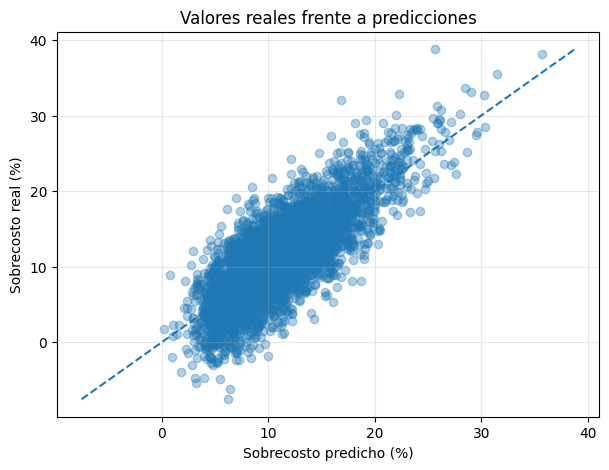

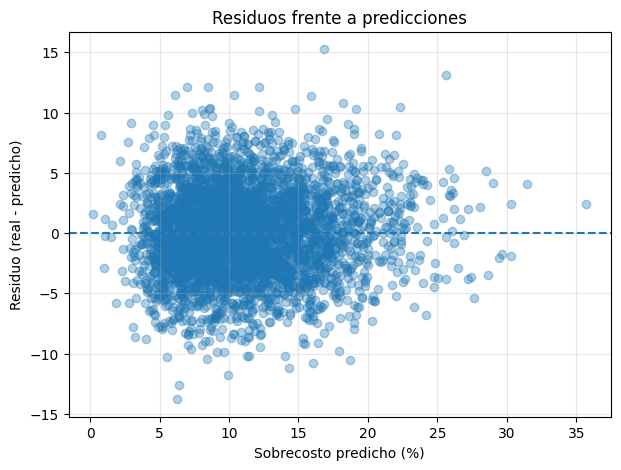

In [22]:
# Residuos: y real frente a predicción y residuo frente a predicción.
pred_pd=(best_test_pred.select("sobrecosto_pct","prediction","tipo_obra")
         .withColumn("residuo",F.col("sobrecosto_pct")-F.col("prediction"))
         .toPandas())

fig,ax=plt.subplots(figsize=(7,5))
ax.scatter(pred_pd["prediction"],pred_pd["sobrecosto_pct"],alpha=.35)
lim_min=min(pred_pd["prediction"].min(),pred_pd["sobrecosto_pct"].min())
lim_max=max(pred_pd["prediction"].max(),pred_pd["sobrecosto_pct"].max())
ax.plot([lim_min,lim_max],[lim_min,lim_max],"--")
ax.set_xlabel("Sobrecosto predicho (%)")
ax.set_ylabel("Sobrecosto real (%)")
ax.set_title("Valores reales frente a predicciones")
ax.grid(True,alpha=.3)
plt.show()

fig,ax=plt.subplots(figsize=(7,5))
ax.scatter(pred_pd["prediction"],pred_pd["residuo"],alpha=.35)
ax.axhline(0,linestyle="--")
ax.set_xlabel("Sobrecosto predicho (%)")
ax.set_ylabel("Residuo (real - predicho)")
ax.set_title("Residuos frente a predicciones")
ax.grid(True,alpha=.3)
plt.show()

In [23]:
# RMSE de prueba por tipo de obra.
rmse_tipo=(pred_pd.groupby("tipo_obra")
           .apply(lambda g: np.sqrt(np.mean(g["residuo"]**2)),include_groups=False)
           .rename("RMSE").reset_index()
           .sort_values("RMSE",ascending=False))
display(rmse_tipo)

,tipo_obra,RMSE
3,Salud,3.685759
4,Saneamiento,3.678846
2,Riego,3.638593
5,Vial,3.553766
1,Educación,3.528750
0,Edificación,3.525026


In [24]:
# Interpretación de pesos en escala original.
# El escalador se ajustó con withMean=True y withStd=True.
# Para y = intercepto + sum(beta_std * ((x-media)/desv)), beta_original=beta_std/desv.
scaler_model=prep.stages[-1]
stds=np.array(scaler_model.std)
means=np.array(scaler_model.mean)
coef_std=np.array(best.coefficients)
coef_original=coef_std/stds
intercept_original=best.intercept-np.sum(coef_std*means/stds)
interpretacion=pd.DataFrame({
    "atributo":atributos,
    "peso_estandarizado":coef_std,
    "desviacion_entrenamiento":stds,
    "peso_escala_original":coef_original
})
display(interpretacion.sort_values("peso_escala_original",key=abs,ascending=False))
print("Intercepto aproximado en escala original:",intercept_original)
print("Para num_adendas, el coeficiente original estima el cambio en puntos porcentuales")
print("de sobrecosto por una adenda adicional, manteniendo constantes los demás atributos.")

,atributo,peso_estandarizado,desviacion_entrenamiento,peso_escala_original
0,num_adendas,3.064181,0.956948,3.202034
9,lluvias,1.139870,0.470962,2.420301
5,log_presupuesto,0.775780,0.918310,0.844791
4,num_postores,-0.535131,1.953764,-0.273898
3,experiencia_contratista_anios,-0.854326,6.647302,-0.128522
2,distancia_capital_km,0.913912,63.700810,0.014347
7,plazo_programado_dias,-0.045022,37.466003,-0.001202
1,altitud_msnm,1.382915,1224.848513,0.001129
6,log_metrado,0.000000,0.893263,0.000000
8,num_trabajadores,0.000000,4.988566,0.000000


Intercepto aproximado en escala original: -5.9815955669386565
Para num_adendas, el coeficiente original estima el cambio en puntos porcentuales
de sobrecosto por una adenda adicional, manteniendo constantes los demás atributos.


In [25]:
# Selección de tres factores para vigilancia: magnitud absoluta de coeficientes originales.
# La priorización debe contrastarse también con correlaciones, estabilidad y RMSE por tipo de obra.
tres_factores=(interpretacion.assign(abs_peso=lambda t: t.peso_escala_original.abs())
               .sort_values("abs_peso",ascending=False).head(3))
display(tres_factores[["atributo","peso_escala_original"]])
print("Conclusión: priorizar estos factores como señales del modelo, no como prueba causal.")

,atributo,peso_escala_original
0,num_adendas,3.202034
9,lluvias,2.420301
5,log_presupuesto,0.844791


Conclusión: priorizar estos factores como señales del modelo, no como prueba causal.


## Cierre y exportación de resultados

Las salidas de las actividades 1 y 2 son cálculos manuales verificables. Las métricas de las actividades 3, 4 y 5 se generan al ejecutar el notebook con el CSV. Para el informe, guardar capturas de: tablas manuales; Ridge/Lasso y LOO; exploración y métricas de modelos; caminos de coeficientes y comparaciones; resultados de CrossValidator y gráficos de residuos.

In [26]:
# Guardar tablas clave como CSV para incorporarlas al informe si se desea.
comparacion_manual.to_csv("actividad1_comparacion_manual.csv",index=False)
ridge_manual.to_csv("actividad2_ridge.csv",index=False)
lasso_manual.to_csv("actividad2_lasso.csv",index=False)
loo_biv.to_csv("actividad2_loo_bivariado.csv",index=False)
loo_mult.to_csv("actividad2_loo_multiple.csv",index=False)
metricas_reg.to_csv("actividad4_metricas_regularizacion.csv",index=False)
print("Tablas exportadas correctamente.")

Tablas exportadas correctamente.
